
# 07 · Hybrid: XGBoost + MLP (Phase 2)

## Objective

Develop and compare hybrid approaches combining the Phase 1 XGBoost model with the Phase 2 MLP.

## Experiments

1. Generate station-based out-of-fold (OOF) XGBoost predictions using GroupKFold.
2. Implement validation-based prediction blending.
3. Implement residual learning using OOF XGBoost predictions.
4. Compare XGBoost, MLP, blending and residual hybrid performance using validation RMSE.
5. Save the selected hybrid validation predictions for technical evaluation.

## Experimental controls

- Random seed: 42.
- Preserve the original station-based train/validation/test split.
- Fit preprocessing separately inside each OOF fold.
- Never use validation or test targets to train the models.
- Select hybrid settings using validation data only.
- Reserve test data for final evaluation.


In [1]:

# 1. Imports and reproducibility

import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
N_SPLITS = 5

np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("Current working directory:", Path.cwd())
print("PyTorch:", torch.__version__)
print("OOF folds:", N_SPLITS)


Project root: /Users/prathapanianusha/water-quality-prediction
Current working directory: /Users/prathapanianusha/water-quality-prediction
PyTorch: 2.15.0
OOF folds: 5


In [7]:

# 2. Load the project data and prepare features

from src.features import (
    load_final_dataset,
    make_features,
    get_xy,
    build_preprocessor,
    FEATURE_COLS,
    TARGET_COL,
)


df = load_final_dataset()
df = make_features(df)

print("Dataset shape:", df.shape)
print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nNumber of unique stations:")
print(df.groupby("split")["site_id"].nunique())

print("\nFeature count:", len(FEATURE_COLS))
print("Target:", TARGET_COL)


Dataset shape: (259774, 29)

Split distribution:
split
train    181747
test      51973
val       26054
Name: count, dtype: int64

Number of unique stations:
split
test     2221
train    6583
val      1136
Name: site_id, dtype: int64

Feature count: 14
Target: target_ccme_value


In [8]:

# 3. Separate data by the original station-based split

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

# Raw model inputs
X_train_raw = train_df[FEATURE_COLS].copy()
X_val_raw = val_df[FEATURE_COLS].copy()
X_test_raw = test_df[FEATURE_COLS].copy()

# Target values
y_train = train_df[TARGET_COL].to_numpy(dtype=np.float32)
y_val = val_df[TARGET_COL].to_numpy(dtype=np.float32)
y_test = test_df[TARGET_COL].to_numpy(dtype=np.float32)

# Station IDs for leakage-safe GroupKFold
groups_train = train_df["site_id"].to_numpy()

# Row IDs for prediction alignment
row_id_train = train_df["row_id"].to_numpy()
row_id_val = val_df["row_id"].to_numpy()
row_id_test = test_df["row_id"].to_numpy()

# Verify station separation
train_sites = set(train_df["site_id"])
val_sites = set(val_df["site_id"])
test_sites = set(test_df["site_id"])

assert train_sites.isdisjoint(val_sites)
assert train_sites.isdisjoint(test_sites)
assert val_sites.isdisjoint(test_sites)

assert len(X_train_raw) == len(y_train) == len(groups_train)
assert len(X_val_raw) == len(y_val) == len(row_id_val)
assert len(X_test_raw) == len(y_test) == len(row_id_test)

print("Training shape:", X_train_raw.shape)
print("Validation shape:", X_val_raw.shape)
print("Test shape:", X_test_raw.shape)

print("\nStation overlap:")
print("Train / Validation:", len(train_sites & val_sites))
print("Train / Test:", len(train_sites & test_sites))
print("Validation / Test:", len(val_sites & test_sites))

print("\nRow ID uniqueness:")
print("Train:", len(np.unique(row_id_train)) == len(row_id_train))
print("Validation:", len(np.unique(row_id_val)) == len(row_id_val))
print("Test:", len(np.unique(row_id_test)) == len(row_id_test))


Training shape: (181747, 14)
Validation shape: (26054, 14)
Test shape: (51973, 14)

Station overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Row ID uniqueness:
Train: True
Validation: True
Test: True


In [9]:
# 4. Verify data alignment and station separation

assert len(X_train_raw) == len(y_train) == len(row_id_train)
assert len(X_val_raw) == len(y_val) == len(row_id_val)
assert len(X_test_raw) == len(y_test) == len(row_id_test)

assert len(groups_train) == len(X_train_raw)

print("Training shape:", X_train_raw.shape)
print("Validation shape:", X_val_raw.shape)
print("Test shape:", X_test_raw.shape)

print("\nStation overlap:")
print("Train / Validation:", len(train_sites & val_sites))
print("Train / Test:", len(train_sites & test_sites))
print("Validation / Test:", len(val_sites & test_sites))

print("\nRow ID uniqueness:")
print("Train:", len(np.unique(row_id_train)) == len(row_id_train))
print("Validation:", len(np.unique(row_id_val)) == len(row_id_val))
print("Test:", len(np.unique(row_id_test)) == len(row_id_test))

print("\nTraining stations:", len(np.unique(groups_train)))

Training shape: (181747, 14)
Validation shape: (26054, 14)
Test shape: (51973, 14)

Station overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Row ID uniqueness:
Train: True
Validation: True
Test: True

Training stations: 6583


In [10]:
# 5. Define the Phase 1 XGBoost configuration

XGB_PARAMS = {
    "objective": "reg:squarederror",
    "n_estimators": 300,
    "max_depth": 8,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 1,
    "random_state": SEED,
    "n_jobs": 1,             # Reduced parallelism to avoid resource overload
    "tree_method": "hist",
    "verbosity": 1,
}

print("XGBoost configuration:")
print(XGB_PARAMS)

print("\nNumber of OOF folds:", N_SPLITS)
print("Unique training stations:", len(np.unique(groups_train)))


XGBoost configuration:
{'objective': 'reg:squarederror', 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1, 'random_state': 42, 'n_jobs': 1, 'tree_method': 'hist', 'verbosity': 1}

Number of OOF folds: 5
Unique training stations: 6583


In [11]:
# 6. Generate station-based out-of-fold XGBoost predictions

oof_xgb = np.full(len(y_train), np.nan, dtype=np.float32)

gkf = GroupKFold(n_splits=N_SPLITS)

for fold, (fit_idx, holdout_idx) in enumerate(
    gkf.split(X_train_raw, y_train, groups=groups_train), start=1
):
    print(f"Training OOF fold {fold}/{N_SPLITS}")

    X_fit = X_train_raw.iloc[fit_idx]
    X_holdout = X_train_raw.iloc[holdout_idx]

    y_fit = y_train[fit_idx]

    # Fit preprocessing only on this fold's training rows
    preprocessor = build_preprocessor(scale=False)

    X_fit_processed = preprocessor.fit_transform(X_fit)
    X_holdout_processed = preprocessor.transform(X_holdout)

    model = XGBRegressor(**XGB_PARAMS)

    model.fit(X_fit_processed, y_fit)

    oof_xgb[holdout_idx] = model.predict(X_holdout_processed)

    print(
        "  Fold RMSE:",
        f"{np.sqrt(mean_squared_error(y_train[holdout_idx], oof_xgb[holdout_idx])):.4f}"
    )

assert not np.isnan(oof_xgb).any()

print("\nOOF predictions generated:", len(oof_xgb))
print("OOF MAE:", mean_absolute_error(y_train, oof_xgb))
print("OOF RMSE:", np.sqrt(mean_squared_error(y_train, oof_xgb)))
print("OOF R²:", r2_score(y_train, oof_xgb))

Training OOF fold 1/5
  Fold RMSE: 10.4346
Training OOF fold 2/5
  Fold RMSE: 10.6287
Training OOF fold 3/5
  Fold RMSE: 10.8435
Training OOF fold 4/5
  Fold RMSE: 10.8554
Training OOF fold 5/5
  Fold RMSE: 10.3281

OOF predictions generated: 181747
OOF MAE: 7.232474327087402
OOF RMSE: 10.620167429838052
OOF R²: 0.29904019832611084


In [12]:

# 7. Train the full-training XGBoost model

full_preprocessor = build_preprocessor(scale=False)

X_train_processed = full_preprocessor.fit_transform(X_train_raw)
X_val_processed = full_preprocessor.transform(X_val_raw)
X_test_processed = full_preprocessor.transform(X_test_raw)

xgb_full = XGBRegressor(**XGB_PARAMS)

xgb_full.fit(X_train_processed, y_train)

# Predictions for validation and test sets
xgb_val_pred = xgb_full.predict(X_val_processed)
xgb_test_pred = xgb_full.predict(X_test_processed)

print("Full-training XGBoost model trained.")
print("Validation predictions:", len(xgb_val_pred))
print("Test predictions:", len(xgb_test_pred))

print("\nValidation XGBoost metrics:")
print("MAE:", mean_absolute_error(y_val, xgb_val_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, xgb_val_pred)))
print("R²:", r2_score(y_val, xgb_val_pred))


Full-training XGBoost model trained.
Validation predictions: 26054
Test predictions: 51973

Validation XGBoost metrics:
MAE: 7.7014055252075195
RMSE: 11.194161078371847
R²: 0.349040687084198


In [13]:

# 8. Load MLP validation predictions and align with XGBoost

mlp_val_df = pd.read_csv("results/dl/predictions_mlp_val.csv")

# Build the XGBoost validation results
xgb_val_df = pd.DataFrame({
    "row_id": row_id_val,
    "y_true": y_val,
    "xgb_pred": xgb_val_pred
})

# Match MLP predictions using row_id
val_compare = xgb_val_df.merge(
    mlp_val_df[["row_id", "y_true", "y_pred"]],
    on="row_id",
    how="inner",
    suffixes=("_xgb", "_mlp"),
    validate="one_to_one"
)

# Verify that both models refer to the same observations and targets
assert len(val_compare) == len(y_val)
assert np.allclose(
    val_compare["y_true_xgb"],
    val_compare["y_true_mlp"],
    atol=1e-5
)

val_compare = val_compare.rename(columns={
    "y_true_xgb": "y_true",
    "y_pred": "mlp_pred"
})

print("Aligned validation observations:", len(val_compare))
print("XGBoost predictions:", len(val_compare["xgb_pred"]))
print("MLP predictions:", len(val_compare["mlp_pred"]))
print("Target alignment verified.")


Aligned validation observations: 26054
XGBoost predictions: 26054
MLP predictions: 26054
Target alignment verified.


In [14]:

# 9. Validation-based blending experiment

blend_results = []

for alpha in np.arange(0, 1.001, 0.05):

    blend_pred = (
        alpha * val_compare["xgb_pred"].to_numpy()
        + (1 - alpha) * val_compare["mlp_pred"].to_numpy()
    )

    blend_results.append({
        "xgb_weight": round(float(alpha), 2),
        "mlp_weight": round(float(1 - alpha), 2),
        "MAE": mean_absolute_error(val_compare["y_true"], blend_pred),
        "RMSE": np.sqrt(
            mean_squared_error(val_compare["y_true"], blend_pred)
        ),
        "R2": r2_score(val_compare["y_true"], blend_pred)
    })

blend_results_df = pd.DataFrame(blend_results)

best_blend = blend_results_df.loc[
    blend_results_df["RMSE"].idxmin()
]

print("Best validation blend:")
print(best_blend)

print("\nAll blending experiments:")
display(blend_results_df.sort_values("RMSE").head(10))


Best validation blend:
xgb_weight     0.550000
mlp_weight     0.450000
MAE            7.678289
RMSE          11.141515
R2             0.355149
Name: 11, dtype: float64

All blending experiments:


,xgb_weight,mlp_weight,MAE,RMSE,R2
11,0.55,0.45,7.678289,11.141515,0.355149
12,0.60,0.40,7.676671,11.141764,0.355120
10,0.50,0.50,7.680924,11.142670,0.355016
13,0.65,0.35,7.675937,11.143417,0.354929
9,0.45,0.55,7.684643,11.145228,0.354719
14,0.70,0.30,7.676178,11.146472,0.354575
8,0.40,0.60,7.689492,11.149188,0.354261
15,0.75,0.25,7.677405,11.150929,0.354059
7,0.35,0.65,7.695488,11.154548,0.353640
16,0.80,0.20,7.679807,11.156785,0.353380


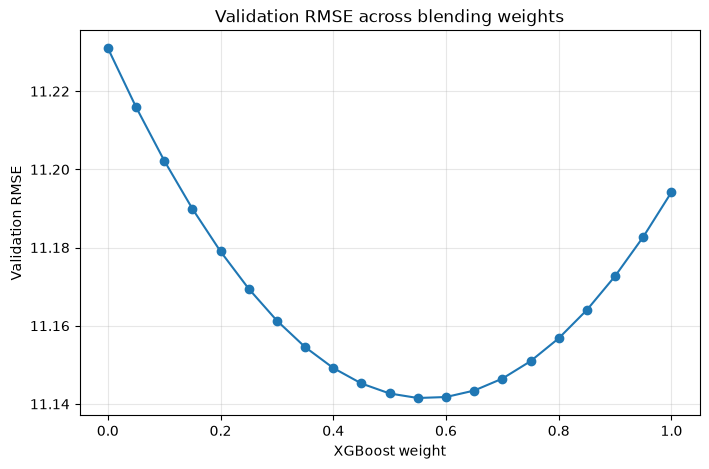

In [15]:

# 10. Plot validation RMSE against XGBoost weight

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    blend_results_df["xgb_weight"],
    blend_results_df["RMSE"],
    marker="o"
)

plt.xlabel("XGBoost weight")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE across blending weights")
plt.grid(True, alpha=0.3)
plt.show()


In [16]:

# 11. Save the best validation blend predictions

best_alpha = float(best_blend["xgb_weight"])

val_compare["blend_pred"] = (
    best_alpha * val_compare["xgb_pred"]
    + (1 - best_alpha) * val_compare["mlp_pred"]
)

output_path = Path("results/hybrid_val_preds.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

val_compare.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Selected XGBoost weight:", best_alpha)
print("Selected MLP weight:", 1 - best_alpha)


Saved: results/hybrid_val_preds.csv
Selected XGBoost weight: 0.55
Selected MLP weight: 0.44999999999999996


In [17]:

# 12. Calculate training residuals using OOF XGBoost predictions

# Ensure predictions and actual values are aligned
assert len(y_train) == len(oof_xgb)
assert not np.isnan(oof_xgb).any()
assert np.isfinite(oof_xgb).all()

# Residual = Actual value - OOF XGBoost prediction
residual_train = y_train - oof_xgb

# Check residual targets
print("Training residuals generated:", len(residual_train))
print("Mean residual:", np.mean(residual_train))
print("Residual standard deviation:", np.std(residual_train))
print("Minimum residual:", np.min(residual_train))
print("Maximum residual:", np.max(residual_train))

# Verify there are no invalid values
assert np.isfinite(residual_train).all()

print("\nResidual target preparation: PASSED")


Training residuals generated: 181747
Mean residual: 0.13244285
Residual standard deviation: 10.619341
Minimum residual: -57.749092
Maximum residual: 43.04712

Residual target preparation: PASSED


In [21]:
# 13. Train residual MLP using OOF XGBoost residuals

import copy
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy import sparse

# Validation residuals are used ONLY for early stopping.
# They are not used to train/update the MLP weights.
residual_val = np.asarray(y_val) - np.asarray(xgb_val_pred)

# Standardise residual targets using TRAINING statistics only
residual_mean = float(np.mean(residual_train))
residual_std = float(np.std(residual_train))

y_res_train_scaled = (residual_train - residual_mean) / residual_std
y_res_val_scaled = (residual_val - residual_mean) / residual_std

# Convert sparse matrices to dense arrays if necessary
if sparse.issparse(X_res_train):
    X_res_train = X_res_train.toarray()

if sparse.issparse(X_res_val):
    X_res_val = X_res_val.toarray()

X_res_train = np.asarray(X_res_train, dtype=np.float32)
X_res_val = np.asarray(X_res_val, dtype=np.float32)

# Convert to tensors
X_train_tensor = torch.tensor(X_res_train, dtype=torch.float32)
y_train_tensor = torch.tensor(
    y_res_train_scaled, dtype=torch.float32
).reshape(-1, 1)

X_val_tensor = torch.tensor(X_res_val, dtype=torch.float32)
y_val_tensor = torch.tensor(
    y_res_val_scaled, dtype=torch.float32
).reshape(-1, 1)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=512,
    shuffle=True
)

# Residual MLP: same hidden-layer structure as tuned MLP
class ResidualMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

torch.manual_seed(SEED)

device = torch.device("cpu")

residual_model = ResidualMLP(X_res_train.shape[1]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    residual_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

best_val_loss = float("inf")
best_state = None
patience = 10
epochs = 60
epochs_without_improvement = 0

for epoch in range(epochs):

    residual_model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        predictions = residual_model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # Validation: no gradient updates
    residual_model.eval()

    with torch.no_grad():
        val_predictions = residual_model(
            X_val_tensor.to(device)
        )
        val_loss = criterion(
            val_predictions,
            y_val_tensor.to(device)
        ).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(residual_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Train loss: {np.mean(train_losses):.5f} | "
            f"Validation residual loss: {val_loss:.5f}"
        )

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best validation checkpoint
residual_model.load_state_dict(best_state)

print("\nResidual MLP training completed.")
print("Best validation residual loss:", best_val_loss)
print("Input features:", X_res_train.shape[1])
print("Device:", device)

Epoch 05 | Train loss: 0.99256 | Validation residual loss: 1.10560
Epoch 10 | Train loss: 0.98660 | Validation residual loss: 1.11048
Epoch 15 | Train loss: 0.97969 | Validation residual loss: 1.11142
Early stopping at epoch 17

Residual MLP training completed.
Best validation residual loss: 1.1025084257125854
Input features: 30
Device: cpu


In [22]:
# 14. Check the residual targets and the trained model's predictions

residual_model.eval()

with torch.no_grad():
    train_res_pred_scaled = residual_model(
        torch.tensor(X_res_train, dtype=torch.float32).to(device)
    ).cpu().numpy().ravel()

    val_res_pred_scaled = residual_model(
        torch.tensor(X_res_val, dtype=torch.float32).to(device)
    ).cpu().numpy().ravel()

# Convert predictions back to the original CCME scale
train_res_pred = train_res_pred_scaled * residual_std + residual_mean
val_res_pred = val_res_pred_scaled * residual_std + residual_mean

print("TRAIN RESIDUALS")
print("Actual mean:", np.mean(residual_train))
print("Actual std:", np.std(residual_train))
print("Predicted mean:", np.mean(train_res_pred))
print("Predicted std:", np.std(train_res_pred))

print("\nVALIDATION RESIDUALS")
print("Actual mean:", np.mean(residual_val))
print("Actual std:", np.std(residual_val))
print("Predicted mean:", np.mean(val_res_pred))
print("Predicted std:", np.std(val_res_pred))

print("\nValidation residual correlation:",
      np.corrcoef(residual_val, val_res_pred)[0, 1])

TRAIN RESIDUALS
Actual mean: 0.13244285
Actual std: 10.619341
Predicted mean: 0.06814593
Predicted std: 1.0537257

VALIDATION RESIDUALS
Actual mean: -0.24473074
Actual std: 11.191485
Predicted mean: -0.070468724
Predicted std: 0.86071855

Validation residual correlation: 0.08773367501097491


In [23]:
# 15. Diagnose residual target scaling and validation data

print("TRAINING")
print("Residual shape:", residual_train.shape)
print("Residual mean:", np.mean(residual_train))
print("Residual std:", np.std(residual_train))
print("Scaled residual mean:", np.mean(y_res_train_scaled))
print("Scaled residual std:", np.std(y_res_train_scaled))

print("\nVALIDATION")
print("y_val shape:", np.asarray(y_val).shape)
print("XGB validation prediction shape:", np.asarray(xgb_val_pred).shape)
print("Residual shape:", np.asarray(residual_val).shape)
print("Residual mean:", np.mean(residual_val))
print("Residual std:", np.std(residual_val))
print("Scaled residual mean:", np.mean(y_res_val_scaled))
print("Scaled residual std:", np.std(y_res_val_scaled))

print("\nPREDICTIONS")
print("Predicted validation residual std:", np.std(val_res_pred))
print("Validation residual correlation:",
      np.corrcoef(residual_val, val_res_pred)[0, 1])

TRAINING
Residual shape: (181747,)
Residual mean: 0.13244285
Residual std: 10.619341
Scaled residual mean: 6.380672e-09
Scaled residual std: 1.0

VALIDATION
y_val shape: (26054,)
XGB validation prediction shape: (26054,)
Residual shape: (26054,)
Residual mean: -0.24473074
Residual std: 11.191485
Scaled residual mean: -0.035517603
Scaled residual std: 1.0538776

PREDICTIONS
Predicted validation residual std: 0.86071855
Validation residual correlation: 0.08773367501097491


In [25]:
# 16. Finalise the selected blending hybrid model

best_xgb_weight = 0.55
best_mlp_weight = 0.45

# Use row-aligned predictions from Cell 11
hybrid_val_pred = (
    best_xgb_weight * val_compare["xgb_pred"].to_numpy()
    + best_mlp_weight * val_compare["mlp_pred"].to_numpy()
)

y_val_aligned = val_compare["y_true"].to_numpy()
xgb_val_aligned = val_compare["xgb_pred"].to_numpy()

hybrid_metrics = {
    "model": "XGBoost_MLP_Blend",
    "MAE": mean_absolute_error(y_val_aligned, hybrid_val_pred),
    "RMSE": np.sqrt(mean_squared_error(y_val_aligned, hybrid_val_pred)),
    "R2": r2_score(y_val_aligned, hybrid_val_pred)
}

xgb_rmse = np.sqrt(
    mean_squared_error(y_val_aligned, xgb_val_aligned)
)

print("SELECTED HYBRID MODEL")
print(hybrid_metrics)

print("\nCOMPARISON WITH XGBOOST")
print("XGBoost RMSE:", xgb_rmse)
print("Hybrid RMSE:", hybrid_metrics["RMSE"])
print("RMSE improvement:", xgb_rmse - hybrid_metrics["RMSE"])

SELECTED HYBRID MODEL
{'model': 'XGBoost_MLP_Blend', 'MAE': 7.678288452064678, 'RMSE': np.float64(11.14151528034008), 'R2': 0.3551491994347836}

COMPARISON WITH XGBOOST
XGBoost RMSE: 11.194161078371847
Hybrid RMSE: 11.14151528034008
RMSE improvement: 0.052645798031766944


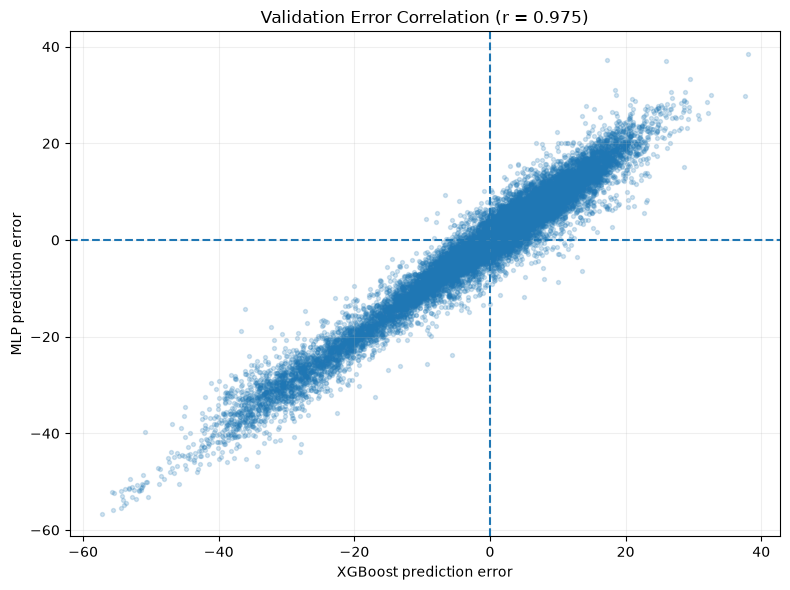

XGBoost–MLP error correlation: 0.9751299114151489


In [26]:
# 17. Compare XGBoost and MLP validation errors

import matplotlib.pyplot as plt

y_true = val_compare["y_true"].to_numpy()
xgb_pred = val_compare["xgb_pred"].to_numpy()
mlp_pred = val_compare["mlp_pred"].to_numpy()

xgb_errors = y_true - xgb_pred
mlp_errors = y_true - mlp_pred

error_correlation = np.corrcoef(xgb_errors, mlp_errors)[0, 1]

plt.figure(figsize=(8, 6))
plt.scatter(xgb_errors, mlp_errors, alpha=0.2, s=8)

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("XGBoost prediction error")
plt.ylabel("MLP prediction error")
plt.title(
    f"Validation Error Correlation (r = {error_correlation:.3f})"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("XGBoost–MLP error correlation:", error_correlation)

## Hybrid Model Pipeline

1. Load the station-based training, validation and test splits.
2. Generate out-of-fold XGBoost predictions on the training data using GroupKFold.
3. Train the MLP using the training features.
4. Generate XGBoost and MLP validation predictions.
5. Evaluate blending weights using validation RMSE.
6. Select the best blend: 55% XGBoost + 45% MLP.
7. Save validation predictions and the selected configuration.
8. Generate final test predictions without using test targets for model selection.

The residual-learning alternative was also investigated using OOF XGBoost residuals, but was not selected because its validation residual predictions had weak correlation with the actual residuals.

In [27]:
# 19. Inspect saved MLP test predictions

mlp_test_path = ROOT / "results" / "dl" / "predictions_mlp.csv"

mlp_test_df = pd.read_csv(mlp_test_path)

print("MLP test prediction columns:")
print(mlp_test_df.columns.tolist())

print("\nShape:", mlp_test_df.shape)
print("\nFirst five rows:")
display(mlp_test_df.head())

print("\nTest split rows:", len(test_df))
print("Test row IDs unique:", test_df["row_id"].is_unique)

MLP test prediction columns:
['row_id', 'y_true', 'y_pred']

Shape: (51973, 3)

First five rows:


,row_id,y_true,y_pred
0,2114,100.0000,82.291794
1,330,93.1167,89.924040
2,2550,93.1167,89.924040
3,205,100.0000,90.040115
4,2580,100.0000,90.040115



Test split rows: 51973
Test row IDs unique: True


In [28]:
# 20. Generate final hybrid test predictions

# Load MLP test predictions
mlp_test_df = pd.read_csv(
    ROOT / "results" / "dl" / "predictions_mlp.csv"
)

# Build XGBoost test prediction dataframe
xgb_test_df = pd.DataFrame({
    "row_id": test_df["row_id"].to_numpy(),
    "xgb_pred": np.asarray(xgb_test_pred).ravel()
})

# Keep only the MLP prediction and row ID
mlp_test_aligned = mlp_test_df[["row_id", "y_pred"]].rename(
    columns={"y_pred": "mlp_pred"}
)

# Merge using row_id
test_compare = xgb_test_df.merge(
    mlp_test_aligned,
    on="row_id",
    how="inner",
    validate="one_to_one"
)

# Verify alignment
assert len(test_compare) == len(test_df)
assert test_compare["row_id"].is_unique
assert set(test_compare["row_id"]) == set(test_df["row_id"])

# Apply selected validation blend weights
test_compare["hybrid_pred"] = (
    best_xgb_weight * test_compare["xgb_pred"]
    + best_mlp_weight * test_compare["mlp_pred"]
)

# Save predictions without calculating test metrics
hybrid_test_output = test_compare[
    ["row_id", "hybrid_pred"]
].rename(columns={"hybrid_pred": "y_pred"})

output_path = ROOT / "results" / "predictions_hybrid.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

hybrid_test_output.to_csv(output_path, index=False)

print("Hybrid test predictions saved.")
print("File:", output_path)
print("Number of predictions:", len(hybrid_test_output))
print("\nFirst five predictions:")
display(hybrid_test_output.head())

Hybrid test predictions saved.
File: /Users/prathapanianusha/water-quality-prediction/results/predictions_hybrid.csv
Number of predictions: 51973

First five predictions:


,row_id,y_pred
0,2114,84.891514
1,330,90.618063
2,2550,90.618063
3,205,93.260350
4,2580,93.260350


In [30]:
# 21. Diagnose hybrid test prediction range

hybrid_test_check = pd.read_csv(
    ROOT / "results" / "predictions_hybrid.csv"
)

print("Number of predictions:", len(hybrid_test_check))
print("Missing predictions:", hybrid_test_check["y_pred"].isna().sum())

print("\nPrediction statistics:")
print(hybrid_test_check["y_pred"].describe())

below_zero = (hybrid_test_check["y_pred"] < 0).sum()
above_100 = (hybrid_test_check["y_pred"] > 100).sum()

print("\nPredictions below 0:", below_zero)
print("Predictions above 100:", above_100)

print("\nLowest predictions:")
display(hybrid_test_check.nsmallest(5, "y_pred"))

print("\nHighest predictions:")
display(hybrid_test_check.nlargest(5, "y_pred"))

Number of predictions: 51973
Missing predictions: 0

Prediction statistics:
count    51973.000000
mean        89.918314
std          7.244797
min         56.493101
25%         84.797976
50%         90.504259
75%         96.695148
max        101.596815
Name: y_pred, dtype: float64

Predictions below 0: 0
Predictions above 100: 471

Lowest predictions:


,row_id,y_pred
1491,110877,56.493101
50416,232652,60.073953
33018,50645,60.086720
49419,229001,60.327930
18093,124892,60.620194



Highest predictions:


,row_id,y_pred
42241,234279,101.596815
50369,232527,101.516107
48696,210555,100.940399
47904,221021,100.909457
48741,210600,100.896241


In [31]:
# 22. Evaluate the effect of clipping on validation predictions

# Original validation predictions
raw_val_pred = hybrid_val_pred.copy()

# Clip predictions to the valid CCME range
clipped_val_pred = np.clip(raw_val_pred, 0, 100)

# Calculate metrics for both versions
raw_metrics = {
    "MAE": mean_absolute_error(y_val_aligned, raw_val_pred),
    "RMSE": np.sqrt(mean_squared_error(y_val_aligned, raw_val_pred)),
    "R2": r2_score(y_val_aligned, raw_val_pred)
}

clipped_metrics = {
    "MAE": mean_absolute_error(y_val_aligned, clipped_val_pred),
    "RMSE": np.sqrt(mean_squared_error(y_val_aligned, clipped_val_pred)),
    "R2": r2_score(y_val_aligned, clipped_val_pred)
}

comparison = pd.DataFrame(
    [raw_metrics, clipped_metrics],
    index=["Unclipped Hybrid", "Clipped Hybrid"]
)

display(comparison)

print("Validation predictions above 100:",
      np.sum(raw_val_pred > 100))

print("Validation predictions below 0:",
      np.sum(raw_val_pred < 0))

,MAE,RMSE,R2
Unclipped Hybrid,7.678288,11.141515,0.355149
Clipped Hybrid,7.675917,11.141434,0.355159


Validation predictions above 100: 217
Validation predictions below 0: 0


In [32]:
# 23. Finalise clipped hybrid validation predictions

hybrid_val_pred = np.clip(hybrid_val_pred, 0, 100)

val_compare["blend_pred"] = hybrid_val_pred

val_output_path = ROOT / "results" / "hybrid_val_preds.csv"
val_compare.to_csv(val_output_path, index=False)

print("Clipped validation predictions saved.")
print("File:", val_output_path)
print("Validation MAE:", mean_absolute_error(y_val_aligned, hybrid_val_pred))
print("Validation RMSE:", np.sqrt(mean_squared_error(y_val_aligned, hybrid_val_pred)))
print("Validation R2:", r2_score(y_val_aligned, hybrid_val_pred))
print("Prediction range:", hybrid_val_pred.min(), "to", hybrid_val_pred.max())

Clipped validation predictions saved.
File: /Users/prathapanianusha/water-quality-prediction/results/hybrid_val_preds.csv
Validation MAE: 7.675917179847454
Validation RMSE: 11.141434006342307
Validation R2: 0.3551586073851485
Prediction range: 55.54953028796387 to 100.0


In [33]:
# 24. Apply the selected clipping rule to test predictions

test_compare["hybrid_pred"] = np.clip(
    test_compare["hybrid_pred"].to_numpy(),
    0,
    100
)

hybrid_test_output = test_compare[
    ["row_id", "hybrid_pred"]
].rename(columns={"hybrid_pred": "y_pred"})

output_path = ROOT / "results" / "predictions_hybrid.csv"
hybrid_test_output.to_csv(output_path, index=False)

print("Final clipped test predictions saved.")
print("File:", output_path)
print("Number of predictions:", len(hybrid_test_output))
print("Prediction range:",
      hybrid_test_output["y_pred"].min(),
      "to",
      hybrid_test_output["y_pred"].max())

Final clipped test predictions saved.
File: /Users/prathapanianusha/water-quality-prediction/results/predictions_hybrid.csv
Number of predictions: 51973
Prediction range: 56.49310113916016 to 100.0


In [34]:
# 25. Verify final hybrid prediction files

val_check = pd.read_csv(
    ROOT / "results" / "hybrid_val_preds.csv"
)

test_check = pd.read_csv(
    ROOT / "results" / "predictions_hybrid.csv"
)

assert len(val_check) == len(y_val_aligned)
assert len(test_check) == len(test_df)

assert val_check["row_id"].is_unique
assert test_check["row_id"].is_unique

assert val_check["blend_pred"].notna().all()
assert test_check["y_pred"].notna().all()

assert val_check["blend_pred"].between(0, 100).all()
assert test_check["y_pred"].between(0, 100).all()

print("ALL HYBRID EXPORT CHECKS PASSED")
print("Validation predictions:", len(val_check))
print("Test predictions:", len(test_check))
print("Validation range:",
      val_check["blend_pred"].min(),
      "to",
      val_check["blend_pred"].max())
print("Test range:",
      test_check["y_pred"].min(),
      "to",
      test_check["y_pred"].max())

ALL HYBRID EXPORT CHECKS PASSED
Validation predictions: 26054
Test predictions: 51973
Validation range: 55.54953028796387 to 100.0
Test range: 56.49310113916016 to 100.0


In [35]:
# 26. Verify reusable hybrid module

from src.hybrid import (
    blend_predictions,
    clip_predictions,
    evaluate_predictions,
    select_blend_weight,
)

# Recreate the selected blend
module_predictions = blend_predictions(
    val_compare["xgb_pred"].to_numpy(),
    val_compare["mlp_pred"].to_numpy(),
    xgb_weight=0.55,
)

module_predictions = clip_predictions(module_predictions)

# Compare with the notebook's final validation predictions
assert np.allclose(module_predictions, hybrid_val_pred)

module_metrics = evaluate_predictions(
    y_val_aligned,
    module_predictions
)

print("Reusable hybrid module verification: PASSED")
print("Metrics:", module_metrics)

Reusable hybrid module verification: PASSED
Metrics: {'MAE': 7.6759175257383285, 'RMSE': 11.14143397688549, 'R2': 0.35515861079493827}


In [36]:
# 27. Re-select blend weight using clipped validation predictions

best_clipped_blend, clipped_weight_results = select_blend_weight(
    y_true=y_val_aligned,
    xgb_pred=val_compare["xgb_pred"].to_numpy(),
    mlp_pred=val_compare["mlp_pred"].to_numpy(),
    weights=np.arange(0, 1.001, 0.05),
    clip=True,
)

print("BEST CLIPPED BLEND")
print(best_clipped_blend)

print("\nTOP 5 WEIGHTS")
display(clipped_weight_results.head())

BEST CLIPPED BLEND
{'xgb_weight': 0.55, 'mlp_weight': 0.44999999999999996, 'MAE': 7.6759175257383285, 'RMSE': 11.14143397688549, 'R2': 0.35515861079493827}

TOP 5 WEIGHTS


,xgb_weight,mlp_weight,MAE,RMSE,R2
0,0.55,0.45,7.675918,11.141434,0.355159
1,0.60,0.40,7.674334,11.141694,0.355129
2,0.50,0.50,7.678484,11.142575,0.355026
3,0.65,0.35,7.673592,11.143345,0.354937
4,0.45,0.55,7.682100,11.145115,0.354732
